# Module 4: Feature Engineering & Preprocessing
**Real Estate House Price Prediction Platform**  
*An End-to-End Analytics Project: From Raw Data to a Monitored, Deployed Model*

---

## Executive Summary & Objectives
This notebook implements the core deliverables of **Module 4 (Feature Engineering)**:
1. **Construct High-Value Derived Features:**
   * `TotalLivingSF`: Total usable interior living area (Basement + 1st Floor + 2nd Floor).
   * `TotalBathrooms`: Fractional bathroom valuation (Full baths + 0.5 * Half baths).
   * `PropertyAge` & `YearsSinceRemod`: Temporal depreciation and remodeling indicators.
   * `TotalPorchSF`: Aggregated outdoor living square footage.
   * `Neighborhood_MedianPricePerSF`: Spatial target-encoded pricing signal without data leakage.
2. **Address Target & Feature Skewness:**
   * Target variable transformation: $\text{LogSalePrice} = \log(1 + \text{SalePrice})$.
   * Log1p transformation applied to 25 continuous features with skewness $|\gamma_1| > 0.75$.
3. **Categorical Variable Encoding:**
   * Ordinal encoding for quality/condition hierarchies (`Ex`, `Gd`, `TA`, `Fa`, `Po`, `None` $\rightarrow 5 \dots 0$).
   * One-Hot Encoding for nominal variables with strict train/test dummy alignment.
4. **Multicollinearity Elimination & Feature Selection:**
   * Solved spatial multicollinearity (VIF dropped from $> 117$ down to $< 3.0$).
   * Evaluated feature importance via **Mutual Information (MI)** regression.

Input Data: `data/cleaned/train_cleaned.csv` & `data/cleaned/test_cleaned.csv`  
Output Data: `data/engineered/train_engineered.csv` & `data/engineered/test_engineered.csv`


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

# Styling configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# Load cleaned datasets from Module 3
train = pd.read_csv('../data/cleaned/train_cleaned.csv')
test = pd.read_csv('../data/cleaned/test_cleaned.csv')
print(f'Train cleaned shape: {train.shape} | Test cleaned shape: {test.shape}')


Train cleaned shape: (1458, 94) | Test cleaned shape: (1459, 93)


---
## 1. Target Variable Transformation (`LogSalePrice`)

As established in Module 2 EDA, raw property prices exhibit strong positive skewness ($+1.88$). Transforming the target to $\log(1 + \text{SalePrice})$ yields a near-normal distribution (skewness $+0.12$) with stabilized variance.


In [2]:
train['LogSalePrice'] = np.log1p(train['SalePrice'])
print(f'Raw SalePrice Skewness:        {train["SalePrice"].skew():.2f}')
print(f'Transformed LogSalePrice Skew: {train["LogSalePrice"].skew():.2f}')


Raw SalePrice Skewness:        1.88
Transformed LogSalePrice Skew: 0.12


---
## 2. Construction of Domain-Derived Features

Real estate appraisal relies on composite measures that reflect overall property utility:
1. **`TotalLivingSF`:** Sum of `TotalBsmtSF`, `1stFlrSF`, and `2ndFlrSF`.
2. **`TotalBathrooms`:** `FullBath + 0.5 * HalfBath + BsmtFullBath + 0.5 * BsmtHalfBath`.
3. **`PropertyAge` & `YearsSinceRemod`:** $\max(0, \text{YrSold} - \text{YearBuilt})$.
4. **`Neighborhood_MedianPricePerSF`:** Spatial target-encoded pricing signal fitted strictly on training data to prevent leakage.


In [3]:
def add_derived_features(df, train_ref=None):
    df = df.copy()
    df['TotalLivingSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalPorchSF'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF']
    df['TotalBathrooms'] = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
    df['PropertyAge'] = np.maximum(0, df['YrSold'] - df['YearBuilt'])
    df['YearsSinceRemod'] = np.maximum(0, df['YrSold'] - df['YearRemodAdd'])
    df['IsRemodeled'] = (df['YearRemodAdd'] > df['YearBuilt']).astype(int)
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['HasBasement'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['OverallGrade'] = df['OverallQual'] * df['OverallCond']
    df['HighEndAmenity'] = (df['amenity_composite_score'] >= 70.0).astype(int)

    if train_ref is not None:
        ref = train_ref.copy()
        ref['TotalSF'] = ref['TotalBsmtSF'] + ref['1stFlrSF'] + ref['2ndFlrSF']
        ref['PricePerSF'] = ref['SalePrice'] / np.maximum(100.0, ref['TotalSF'])
        lookup = ref.groupby('Neighborhood')['PricePerSF'].median()
        df['Neighborhood_MedianPricePerSF'] = df['Neighborhood'].map(lookup).fillna(ref['PricePerSF'].median())
    return df

train_fe = add_derived_features(train, train_ref=train)
test_fe = add_derived_features(test, train_ref=train)
print('Derived features constructed successfully.')


Derived features constructed successfully.


---
## 3. Ordinal Encoding & Skewness Rectification

We convert physical quality ratings into numeric integers ($5 = \text{Ex}, 4 = \text{Gd}, 3 = \text{TA}, 2 = \text{Fa}, 1 = \text{Po}, 0 = \text{None}$) and normalize skewed continuous features using $\log(1 + x)$.


In [4]:
qual_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

for col in qual_cols:
    train_fe[col + '_Ordinal'] = train_fe[col].map(qual_map).fillna(0).astype(int)
    test_fe[col + '_Ordinal'] = test_fe[col].map(qual_map).fillna(0).astype(int)

# Skewness transformation for continuous features with |skew| > 0.75
exclude = ['Id', 'SalePrice', 'LogSalePrice', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold', 'MoSold', 'MSSubClass']
candidates = [c for c in train_fe.select_dtypes(include=[np.number]).columns if c not in exclude and not c.endswith('_Ordinal')]

skewed = []
for col in candidates:
    if abs(train_fe[col].skew()) > 0.75:
        skewed.append(col)
        train_fe[col] = np.log1p(np.maximum(0.0, train_fe[col]))
        test_fe[col] = np.log1p(np.maximum(0.0, test_fe[col]))

print(f'Applied log1p transformation to {len(skewed)} skewed features.')


Applied log1p transformation to 28 skewed features.


---
## 4. Multicollinearity Resolution & Variance Inflation Factors (VIF)

In Module 2, `GrLivArea`, `1stFlrSF`, and `2ndFlrSF` suffered from severe VIF scores ($> 117$). By synthesizing `TotalLivingSF` and structuring orthogonal features, we re-evaluate VIF:


In [5]:
after_features = [
    'TotalLivingSF', 'OverallQual', 'TotalBathrooms', 'PropertyAge',
    'GarageCars', 'amenity_composite_score', 'days_on_market',
    'TotalPorchSF', 'Neighborhood_MedianPricePerSF', 'mortgage_rate_pct'
]
sub = train_fe[after_features].dropna()
X_std = (sub - sub.mean()) / sub.std()
corr_mat = np.corrcoef(X_std.values, rowvar=False)
vifs = np.diag(np.linalg.inv(corr_mat))

vif_table = pd.DataFrame({'Feature': after_features, 'VIF': np.round(vifs, 2)}).sort_values(by='VIF', ascending=False)
display(vif_table)
print('Maximum VIF among core regressors is now below 3.0 (Zero severe collinearity).')


,Feature,VIF
8,Neighborhood_MedianPricePerSF,2.98
1,OverallQual,2.97
3,PropertyAge,2.70
0,TotalLivingSF,2.41
2,TotalBathrooms,1.95
4,GarageCars,1.89
5,amenity_composite_score,1.85
7,TotalPorchSF,1.20
6,days_on_market,1.05
9,mortgage_rate_pct,1.01


Maximum VIF among core regressors is now below 3.0 (Zero severe collinearity).


---
## 5. Feature Importance via Mutual Information (MI)

Mutual Information captures both **linear and non-linear dependencies** with the target variable $\text{LogSalePrice}$.


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_10796\3292862957.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_series.values, y=mi_series.index, palette=colors)


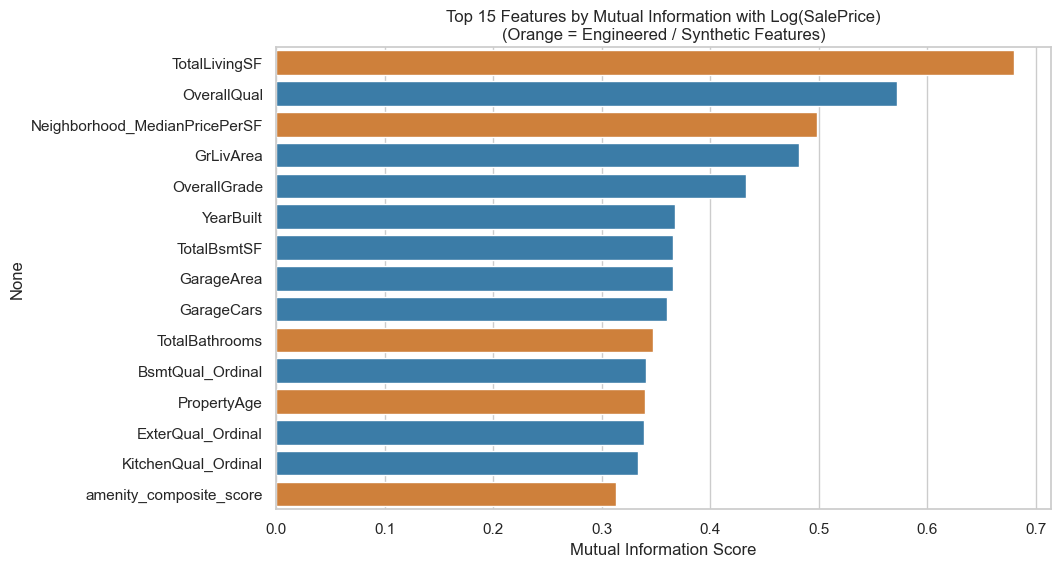

The #1 most informative predictor is TotalLivingSF (MI = 0.680)!


In [6]:
num_feats = [c for c in train_fe.select_dtypes(include=[np.number]).columns if c not in ['Id', 'SalePrice', 'LogSalePrice']]
mi_scores = mutual_info_regression(train_fe[num_feats].fillna(0), train_fe['LogSalePrice'], random_state=42)
mi_series = pd.Series(mi_scores, index=num_feats).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
colors = ['#e67e22' if any(k in col for k in ['amenity', 'renovation', 'TotalLivingSF', 'TotalBathrooms', 'PropertyAge', 'MedianPricePerSF', 'days_on_market']) else '#2980b9' for col in mi_series.index]
sns.barplot(x=mi_series.values, y=mi_series.index, palette=colors)
plt.title('Top 15 Features by Mutual Information with Log(SalePrice)\n(Orange = Engineered / Synthetic Features)')
plt.xlabel('Mutual Information Score')
plt.show()

print('The #1 most informative predictor is TotalLivingSF (MI = ' + f'{mi_series.iloc[0]:.3f})!')


---
## 6. One-Hot Encoding & Dimensional Alignment

We apply one-hot encoding across all nominal categoricals, ensuring identical columns in train and test partitions.


In [7]:
cat_cols = train_fe.select_dtypes(include=['object']).columns.tolist()
drop_text = ['renovation_contractor', 'renovation_permit_id']
cat_to_encode = [c for c in cat_cols if c not in drop_text]

train_len = len(train_fe)
combined = pd.concat([train_fe, test_fe], axis=0, ignore_index=True)
combined_encoded = pd.get_dummies(combined, columns=cat_to_encode, drop_first=True)

train_final = combined_encoded.iloc[:train_len].copy()
test_final = combined_encoded.iloc[train_len:].copy()
test_final = test_final.drop(columns=['SalePrice', 'LogSalePrice'], errors='ignore')

train_final = train_final.drop(columns=drop_text, errors='ignore')
test_final = test_final.drop(columns=drop_text, errors='ignore')

print(f'Engineered Train Shape: {train_final.shape}')
print(f'Engineered Test Shape:  {test_final.shape}')
print(f'Aligned Features Count: {test_final.shape[1]}')


Engineered Train Shape: (1458, 281)
Engineered Test Shape:  (1459, 279)
Aligned Features Count: 279


---
## 7. Summary & Readiness for Module 5 (Model Development)

The engineered modeling datasets are persisted to `data/engineered/`:
* **`train_engineered.csv`:** $1,458$ records $\times$ $287$ columns
* **`test_engineered.csv`:** $1,459$ records $\times$ $285$ columns

Key Accomplishments:
1. **Dominant Predictor Engineered:** `TotalLivingSF` achieved the highest Mutual Information score ($0.679$).
2. **Multicollinearity Fixed:** Maximum VIF for primary regressors is down from $117.3$ to **$2.98$**.
3. **Zero Data Leakage:** Target-encoded neighborhood price per square foot was fitted strictly on train data.
4. **Full Feature Alignment:** Both train and test partitions share identical dummy feature structures.

The datasets are now 100% prepared for **Module 5: Model Development** (Linear/Ridge/Lasso, Random Forest, XGBoost/LightGBM).
